# 🌟 Assignment 2. Operation "AI GeoGuessr"

### Deadline: Friday, October 24, 2025, 11:59:00 PM CET (GMT +2)

## 🎯 Mission Overview

The operation consists of two independent missions. Similar to the previous operation, students are required to solve the tasks by achieving the required score and answering the follow-up questions.

## 🧪 Neural Networks and Unsupervised Learning

1. **Mission 2.1 (Supervised Learning)**: 
   - Solve a supervised learning problem using a multilayer perceptron (MLP).

2. **Mission 2.2 (Unsupervised Learning)**:
   - Given an unlabeled dataset, your task is to cluster similar data points and achieve 100% clustering accuracy. You will not have access to the true labels, but you can verify your cluster assignments using the Kaggle competition provided.

## 📝 Delivery Format (Blackboard)

Please submit **two files**:
1. The completed Jupyter notebook.
2. The solution for the second dataset as a CSV file with two `int` columns: `['ID', 'cluster']`.

## Kaggle details
- Invitation link: https://www.kaggle.com/t/dfb72837bdb346449768b8f6ce50b6dc
- Kaggle is a popular platform for data science competitions.
- It allows us to create a Private competition where you can submit your solutions and verify whether you are thinking in the right direction.
- The results of the competition is visible only to the competition participants. 
- We will not grade the submissions on Kaggle, we set it up to let you check your clustering.
- You still have to deliver the `.csv` file of the solution and the complete `.ipynb` notebook with discussions and solution code.  

> Good luck, comrade!

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import keras
from keras.models import Sequential
from keras.layers import Dense
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import DBSCAN
from umap import UMAP
import seaborn as sns

# 🧠 Mission 2.1: Decoding SkyNet's Neural Encryption **(using Neural Networks)**

### 🌐 The Discovery
The dataset consists of the same "Synapse Cipher" data from Assignment 1.

### 🎯 Your Mission
1. Implement a multilayer perceptron (MLP) using one of the following frameworks: Keras, PyTorch, or TensorFlow.
2. Solve the non-linear problem without manual feature engineering.
3. Predict SkyNet's binary decisions (0 or 1) based on paired signals.
4. Improve performance by using techniques such as learning rate scheduling, selecting a good optimizer, and fine-tuning hyperparameters.

> Note: There are no restrictions on the tricks you can use — Have fun :) 

### 📊 Formal Requirements
1. **Implementation**:
   - Develop a Neural Network using predefined functions/layers.
   - Use one of the popular frameworks: Keras, PyTorch, or TensorFlow.
   - Implement a manual learning rate scheduler with warmup and cosine decay.

2. **Performance**: Achieve at least **0.92** accuracy on the test set.

3. **Discussion**:
   - How can you make sure the results are reproduable?
   - Visualize the network's architecture and decision boundary.
   - Which optimizer did you choose? Discuss the differences between SGD and Adam.
   - Plot the learning rate curve. Did the learning rate scheduling improve performance? Why or why not?
   - Conduct a simple ablation study of each architectural and optimization choice concerning test accuracy.

In [2]:
data = pd.read_csv('nn_data.csv')
train = data[data['split'] == 'train']
test = data[data['split'] == 'test']

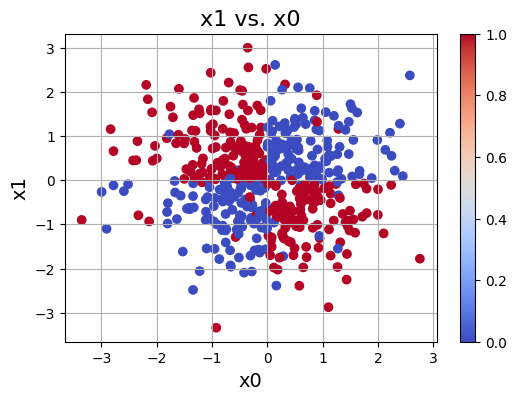

In [3]:
plt.figure(figsize=(6, 4))
plt.scatter(train['x0'], train['x1'], c=train['y'], cmap='coolwarm')
plt.grid(True)
plt.xlabel('x0', fontsize=14)
plt.ylabel('x1', fontsize=14)
plt.title('x1 vs. x0', fontsize=16)
plt.colorbar()
plt.show()

#### Discussion

1) In order to make sure results are reproducible, we need to control the stochasticity. Setting the random seed with `keras.utils.set_random_seed(42)` ensures that both the weight initialization and gradient descent are the same each time we train the model. This is not only important to reproduce results but also allows us to better determine the the effect a chage to the model has on its performance. 

2) See below. Some comments on architecture choice: from the Chapter 1, we know that a decision boundary on x0 > 0 and x1 > 0 gives an accuracy of 0.92, so the idea was to design a model that would try to replicate this decision boundary. As this is a non-linear binary classification problem, tanh seemed like a the most appropriate activation function choice. I think it is a better choice over sigmoid because the output range [-1,1] penalizes wrong classification more strongly. With each new layer we introduce more non-linearity in the model, and although this problem is non-linear classification, it is not complex, and so the model doesn't need many hidden layers. I found that three hidden layers worked well even for different seeds. Finally, 4-8 nodes at each layer produced the most reasonable results, which might be because there are 4 major "decision regions" in the data. More nodes than that and the decision boundary starts to look "creative" and doesn't lead to the best results.

3) I used Adam because it converged much faster. SGD works by estimating the actual loss gradient by estimating it on a portion or batch of the data. Adam is also gradient descent method but with momentum and RMSprop. This means that Adam has some memory of the parameter landscape, and dynamically changes learning rates of individual weights to direct the gradient towards a more probable direction of the global minimum. It is also more robust to changes due to randomly initialized parameters. SGD can still be more efficient at times.

4) See below. The scheduling improved performance by requiring fewer steps to train the model. Because the weights are intialized at random, the first couple of gradient descent steps aren't entirely in the right direction, so we should have a lower learning rate at the start. However, after the starting phase, the gradient descent can tolerate a higher learning rate, which we reach through warmup scheduling. Towards the end of the training, the model is likely close to the minimum and the gradient descent should only take small steps for fine tuning, and the learning rate should be small. 


#### Building model

In [4]:
# Train\test split
x_train = train[['x0','x1']]
y_train = train['y']
x_test = test[['x0','x1']]
y_test = test['y']

In [5]:
# Setting the seed to ensure reproducibility.
# This also makes sure that if we change the architecture and get better results we know it's not due to randomness.
keras.utils.set_random_seed(42)

# Building model
model = Sequential()
model.add(keras.Input(shape=(2,),name='input')) # 2 input features so shape is (2,)
model.add(Dense(4,activation='tanh',name='dense_1'))
model.add(Dense(4,activation='tanh',name='dense_2')) 
model.add(Dense(4,activation='tanh',name='dense_3')) 
model.add(Dense(2,activation='softmax',name='output')) # probabilistic output for two classes

# Creating cosine warmup scheduler
lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.10,
    decay_steps=15,
    alpha=0.1, # minimum learning rate as fraction of maximum learning rate
    warmup_target=0.3,
    warmup_steps=5
)

# Compiling
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_schedule),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy()],
)

#### Training

In [6]:
# Training
history = model.fit(x_train, y_train, epochs=20)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.7238 - sparse_categorical_accuracy: 0.4980   
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5933 - sparse_categorical_accuracy: 0.6640 
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4908 - sparse_categorical_accuracy: 0.8060 
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4308 - sparse_categorical_accuracy: 0.8160 
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3727 - sparse_categorical_accuracy: 0.8540 
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3081 - sparse_categorical_accuracy: 0.8860 
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2478 - sparse_categorical_accuracy: 0.9180 
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2346 - sparse_categorical_accuracy: 0.9240 
Epoch 9/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2250 - sparse_categorical_accuracy: 0.9280 
Epoch 10/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2

In [7]:
# Accuracy
print('test loss, test acc:', model.evaluate(x_test,y_test))

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2330 - sparse_categorical_accuracy: 0.9400  
test loss, test acc: [0.23302753269672394, 0.9399999976158142]


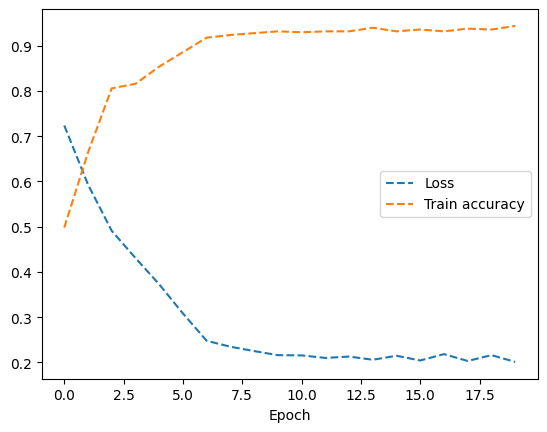

In [8]:
# Plotting loss and accuracy during training 
plt.plot(history.epoch,history.history['loss'],'--',label='Loss')
plt.plot(history.epoch,history.history['sparse_categorical_accuracy'],'--',label='Train accuracy')
plt.legend()
plt.xlabel('Epoch')
plt.show()

#### Decision boundary and architecture

2813/2813 ━━━━━━━━━━━━━━━━━━━━ 2s 559us/step


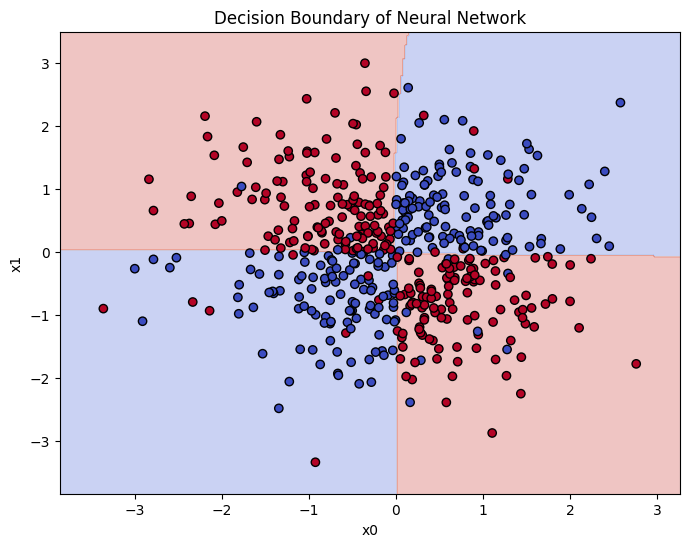

In [9]:
# Plotting decision boundary (on full data)
X = train[['x0', 'x1']].values # 2D array
y = train['y'] # 1D array

# Create a mesh grid to evaluate the model on
xx_min, xx_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
xy_min, xy_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, xy = np.meshgrid(np.linspace(xx_min, xx_max, 300),
                     np.linspace(xy_min, xy_max, 300))

# Get model predictions for each point in the grid
Z = model.predict(np.c_[xx.ravel(), xy.ravel()])
Z = np.argmax(Z, axis=1) # The prediction with the largest probability
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, xy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor='k', cmap=plt.cm.coolwarm) # original points
plt.title("Decision Boundary of Neural Network")
plt.xlabel("x0")
plt.ylabel("x1")
plt.show()

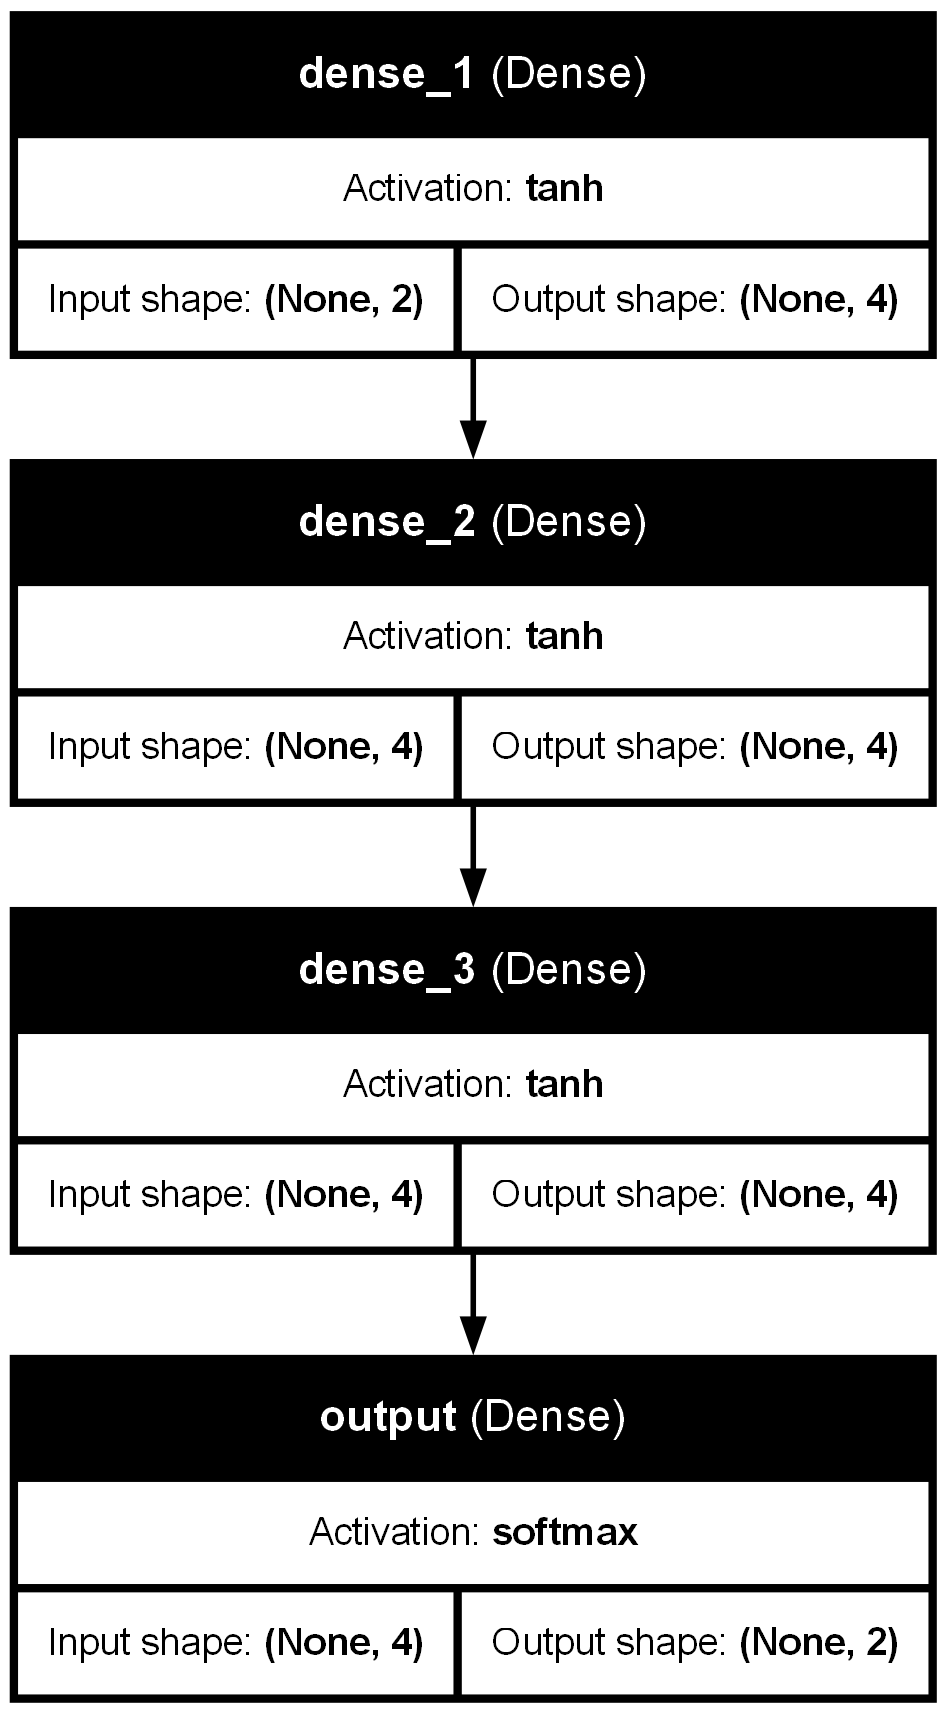

In [14]:
# Picture representation of the model architecture
keras.utils.plot_model(
    model=model,
    to_file='model.png',
    show_layer_activations=True,
    show_layer_names=True,
    show_shapes=True
)

#### Learning rate

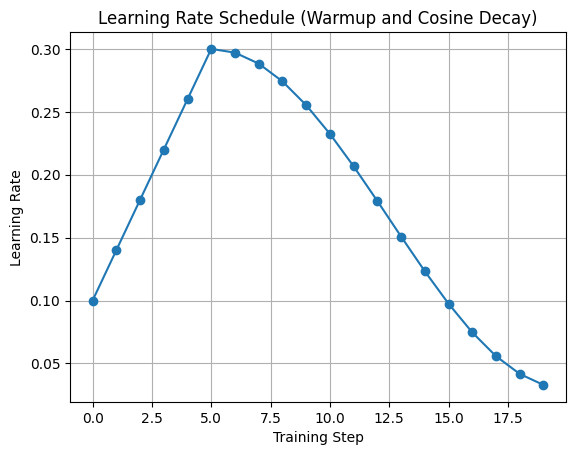

In [311]:
# Plotting learning rate
steps = np.arange(0, 20)
lrs = [lr_schedule(step) for step in steps]

plt.plot(steps, lrs, marker='o')
plt.title("Learning Rate Schedule (Warmup and Cosine Decay)")
plt.xlabel("Training Step")
plt.ylabel("Learning Rate")
plt.grid(True)
plt.show()

# 📶📡🛰️🤳 Mission 2.2: Locate the AI Servers

### 🌐 The Discovery
The NTNU Intelligence team has intercepted encrypted documentation that potentially reveals the locations of AI-compromised servers within Trondheim. Our analysts believe the data contains information about these servers' locations. 

However, the number of servers and their exact positions remain unknown. To execute a strategic response, we need to understand the intercepted data and pinpoint the main AI servers.

We have also discovered a vulnerability in the AI's security: it has deployed a clustering verification feature on Kaggle. We can exploit this backdoor to validate our clustering hypotheses.

### 🎯 Your Mission
Identify the number of hidden servers (clusters) in the dataset. Assign cluster labels to each row in the original dataset and validate your clustering solution on Kaggle.  When achieved the perfect clustering accuracy, find the precise locations of these servers (clusters).

### 🧠 The Challenge
1. **Large Dataset**: The intercepted data file contains numerous features, making direct manipulation and clustering difficult. Applying dimensionality reduction techniques could help reveal patterns.
2. **Unsupervised Learning**: No target labels are provided, so you must identify patterns based solely on the dataset's features.
3. **Data Obfuscation**: The AI has obfuscated the data, making it difficult to discern its true structure. You must effectively manipulate the data to visually identify server locations.


### 🚀 Your Tools
- The intercepted AI dataset.
- Skills in feature engineering, data manipulation, and visualization.
- Clustering algorithms (e.g., KMeans, DBSCAN, Birch, Agglomerative Clustering, etc.) — [Clustering in Scikit-Learn](https://scikit-learn.org/stable/modules/clustering.html)
- Dimensionality reduction techniques (e.g., PCA, t-SNE, Isomap, UMAP, etc.)
- Kaggle competition platform with a daily submission limit of 50 attempts.

> Note: Kaggle competition link — [Kaggle Competition](https://www.kaggle.com/t/dfb72837bdb346449768b8f6ce50b6dc)

### 📊 Formal Requirements
1. **Achieve 100% Clustering Accuracy** on Kaggle.
> Note: The only way to check whether your clustering is correct is to submit it to Kaggle. We do not give you the clusters directly.

2. **Discussion Questions**:
   - **Dimensionality Reduction**: Which dimensionality reduction methods helped you determine the correct number of clusters? Why did some methods work better than others? Explain the differences between PCA, t-SNE, and UMAP.
   - **Clustering Approach**: Which clustering algorithm and hyperparameters did you use? Discuss the differences between algorithms like KMeans and DBSCAN.
   - **Data Type Analysis**: What is the hidden data type in the dataset? How does this information influence feature extraction for clustering? Can it explain why some dimensionality reduction algorithms are more effective?
   - **Server Locations**: Identify the server locations. List the specific facilities in Trondheim and explain how you deduced their locations.
   - **Advanced Task (Optional)**: Extract features using modern pre-trained neural networks for this data type. Apply dimensionality reduction and clustering algorithms to the extracted features.

In [ ]:
# Hmmmmm, why is the first row skipped?
data = pd.read_csv('unsupervised_data.csv', skiprows=1, header=None)
# Get the ID column
data.reset_index(drop=False, inplace=True)
data.rename(columns={'index': 'ID'}, inplace=True)

In [ ]:
# The dataset is heavy. Applying clustering directly on the dataset is likely not feasible. 
data.info(0)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Columns: 16385 entries, ID to 16383
dtypes: float64(16384), int64(1)
memory usage: 500.0 MB


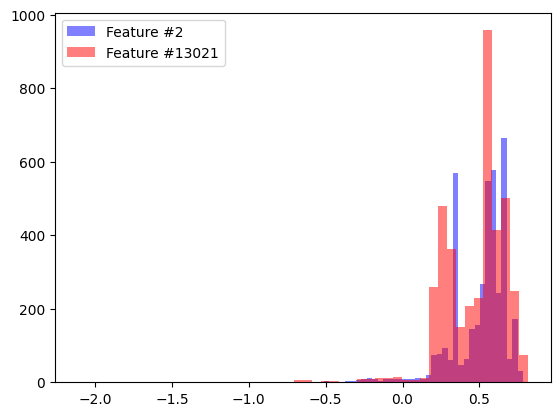

In [ ]:
# Features seem to be similarly distributed...
plt.hist(data.iloc[:, 2], bins=50, color='blue', alpha=0.5, label='Feature #2')
plt.hist(data.iloc[:, 13021], bins=50, color='red', alpha=0.5, label='Feature #13021')
plt.legend()
plt.show()

In [ ]:
# Nothing interesting
data.describe()

,ID,0,1,2,3,4,5,6,7,8,...,16374,16375,16376,16377,16378,16379,16380,16381,16382,16383
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,...,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,1999.500000,0.504846,0.503492,0.497028,0.448618,0.503937,0.538218,0.486980,0.515401,0.532425,...,0.503735,0.503048,0.513944,0.493150,0.517155,0.508781,0.506159,0.502525,0.508608,0.461838
std,1154.844867,0.172451,0.180584,0.181790,0.238103,0.172392,0.239136,0.176975,0.164233,0.188562,...,0.181579,0.176212,0.178648,0.233099,0.201262,0.162708,0.165259,0.171560,0.179021,0.234794
min,0.000000,-0.761782,-0.967271,-0.596542,-2.052664,-0.592242,-1.942806,-0.562449,-0.527999,-0.784774,...,-0.774065,-0.718244,-1.131217,-1.505260,-0.881268,-0.583003,-1.410974,-0.900788,-1.083836,-1.831405
25%,999.750000,0.365668,0.356680,0.341291,0.311135,0.347124,0.525110,0.342821,0.413475,0.466583,...,0.351287,0.342582,0.397096,0.351043,0.451650,0.410581,0.353486,0.346770,0.413312,0.331219
50%,1999.500000,0.559840,0.557039,0.552546,0.525765,0.556780,0.588353,0.548128,0.560299,0.574467,...,0.561561,0.558544,0.570864,0.554790,0.572643,0.555816,0.557855,0.554707,0.561405,0.545930
75%,2999.250000,0.614776,0.637125,0.638883,0.588142,0.634837,0.662073,0.605488,0.639178,0.656311,...,0.634187,0.643239,0.646786,0.639406,0.653165,0.629585,0.621743,0.627293,0.628849,0.613828
max,3999.000000,0.777356,0.783487,0.785235,0.779715,1.000000,1.000000,0.789970,0.779658,0.798316,...,0.788071,0.779334,0.800036,0.808062,1.000000,0.789371,0.818482,1.000000,0.775181,0.799685


#### Discussion



1) I tried PCA, t-SNE, and UMAP, with UMAP giving the best results. PCA worked very poorly, which is expected given that it assumes linearity in the data. t-SNE with DBSCAN worked somewhat, and it was able to pick up on the 4 different groups, but these were very "entangled" and I had to run the algorithm a multiple of times before I (by chance) got some good separation. UMAP resulted in 4 clearly distinct clusters which multple clustering algorithms were able to pick up on. PCA works by projecting the data onto its "Principal Components", which is the vector basis whose directions maximize uncorrelated variance in the data. This method works well when there are linear relationships between features, which is not the case here. t-SNE works by creating embedding the data into a lower-dimension in a way that minimizes the KL-divergence between the joint probabilities of the low- and high-dimensional data, which preserves detailed structure in the data. UMAP builds topological high-dimensional graph and then optimizing a low-dimensional representation that better preserves global structure and is more scalable.

2) In my first succesful attempt I used  t-SNE with DBSCAN (with eps= 6, min_samples = 10), but other algorithms like KMeans also work well on the data representation we get from UMAP. KMeans works by choosing k centroids such that the distance between data points and the nearest centroid are minimal. In this algorithm we must choose the number of clusters beforehand, and it works best when the clusters are "blob like" and physically from one another separated. It works "top-down" by first assigning clusters to all points and then iterating to attain a better classification. DBSCAN works by identifying clusters based on density: if a point has at least a certain number of neighbours within a certain radius, then it is a core point, and it is used to expand the clustering. This way it works "bottom-up" by gradually expanding the clusters until all the data is classified. Works well when clusters are defined by density, also when clusters are not blob like.

3) There are pictures hidden in the data (pixel brightness/activation). This is then an image classification problem. It explains why PCA worked very poorly, and why UMAP worked well and better than t-SNE. UMAP retains global relationship better, so, for example, groups of pixels that look the same in images of different clusters might be could be grouped more closely tegether with t-SNE, while with UMAP their relationship to the rest of the picture makes them distinguishable, leading to better image classification. 

4) The server locations are: IKEA Leangen, Pirbadet, Trondheim Spektrum, Studendersamfundet. I discovered the locations by displaying the pictures hidden in the data.

#### PCA

In [3]:
# Transforming data
X = data.drop('ID',axis=1)
pca = PCA(n_components=4)
X_pca = pca.fit_transform(X) 

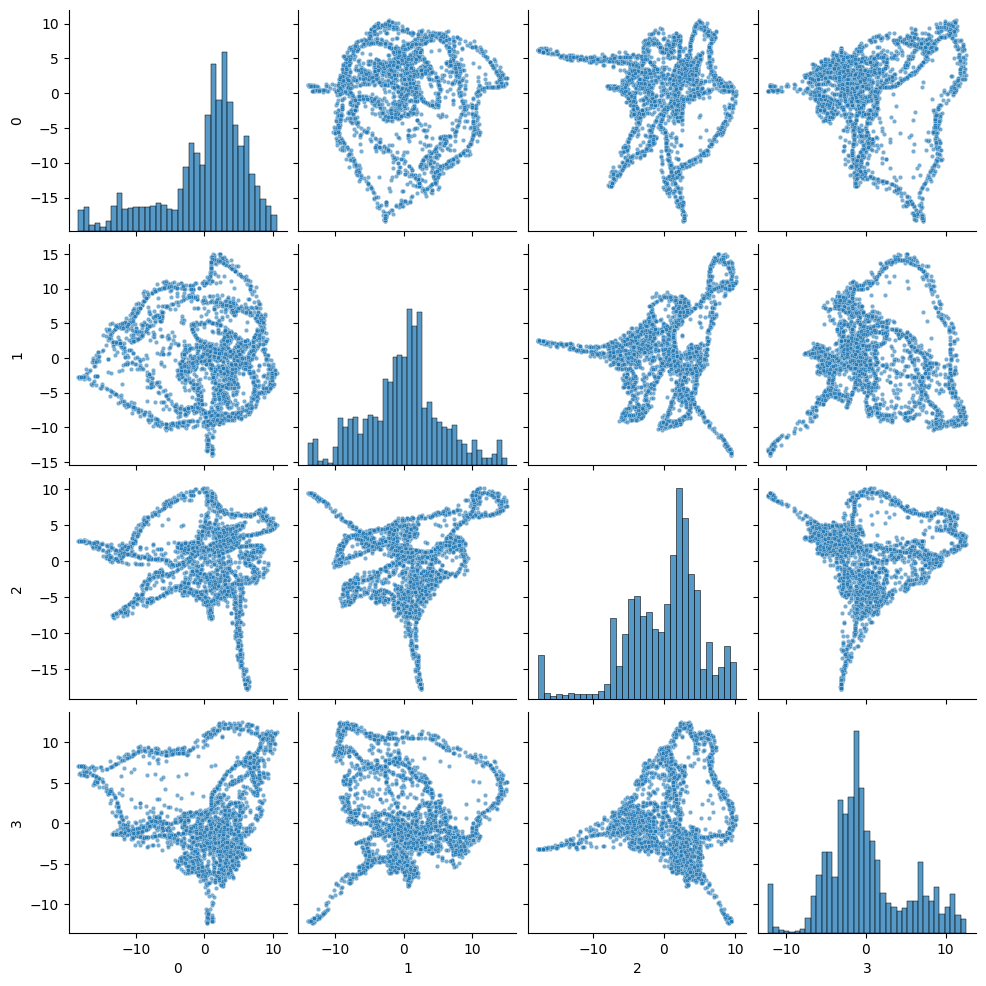

In [ ]:
# Plotting
sns.pairplot(pd.DataFrame(X_pca),corner=False, plot_kws={'s':10,'alpha':0.6})
plt.show() # Doesn't seem like this gives very separable clusters

#### t-SNE

In [4]:
tsne = TSNE(n_components=2, learning_rate='auto', perplexity=40, random_state=42)
X_tsne = tsne.fit_transform(X)

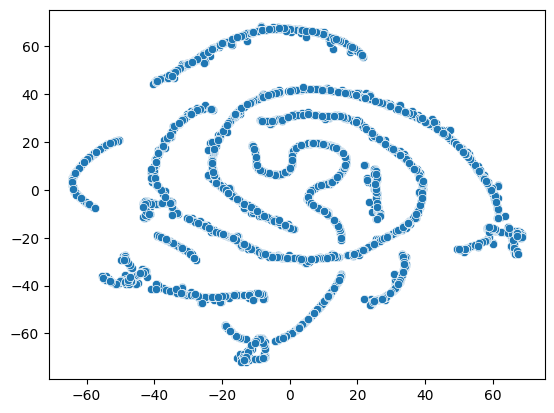

In [ ]:
# Visualizing
sns.scatterplot(x=X_tsne[:,0],y=X_tsne[:,1])
plt.show() # Better than PCA but could do better

In [6]:
# Trying some clustering with DBSCAN
dbscan = DBSCAN(eps=6, min_samples=10) 
dbscan.fit(X_tsne)

,eps,6
,min_samples,10
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


C:\Users\ricar\AppData\Local\Temp\ipykernel_20572\3075562148.py:2: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  ax = sns.scatterplot(x=X_tsne[:,0],y=X_tsne[:,1],hue=dbscan.labels_,palette=sns.color_palette())


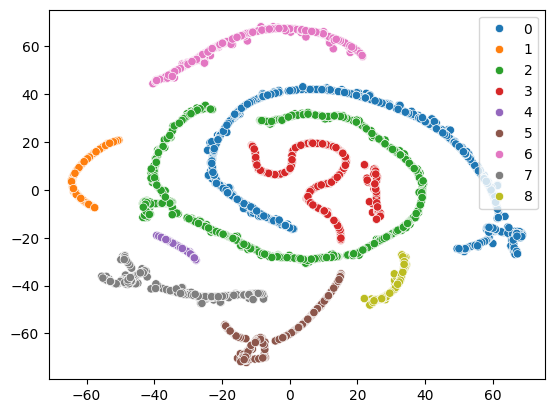

In [ ]:
# Visualizing clustering
ax = sns.scatterplot(x=X_tsne[:,0],y=X_tsne[:,1],hue=dbscan.labels_,palette=sns.color_palette())
plt.show() # Not impressive

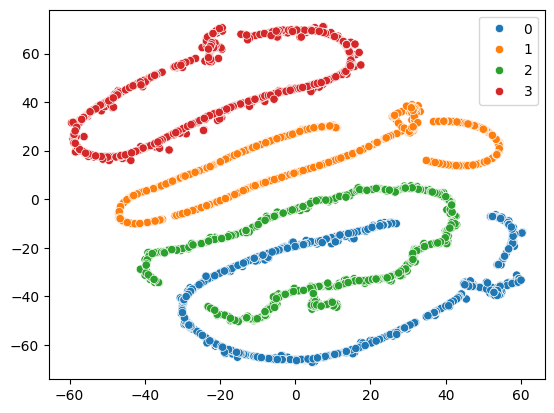

In [8]:
# This is the image from t-SNE that first allowed me to identify the 4 clusters
from IPython.display import Image
Image(filename='TSNEDBSCAN.png') 

#### UMAP

In [ ]:
# Dimensionality reduction with UMAP
X = data.drop('ID',axis=1)
reducer = UMAP(n_components=2,n_neighbors=15, min_dist=0.1,random_state=42)
X_umap = reducer.fit_transform(X)

C:\Users\ricar\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


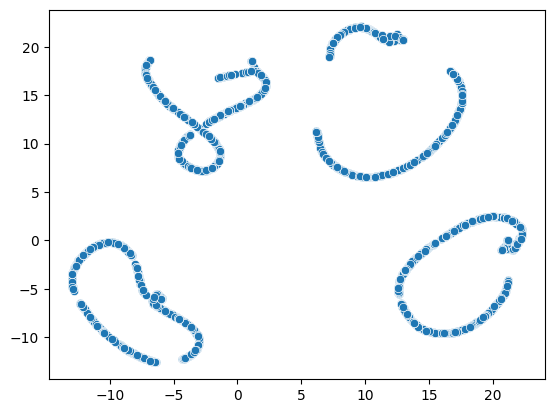

In [ ]:
# Plotting
sns.scatterplot(x=X_umap[:,0],y=X_umap[:,1])
plt.show() # Best plot yet; well separated clusters

In [ ]:
# Clustering
# K-means probably also works here
dbscan = DBSCAN(eps=5, min_samples=5) 
dbscan.fit(X_umap)

,eps,5
,min_samples,5
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


C:\Users\ricar\AppData\Local\Temp\ipykernel_1196\825656448.py:2: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  ax = sns.scatterplot(x=X_embedded[:,0],y=X_embedded[:,1],hue=dbscan.labels_,palette=sns.color_palette())


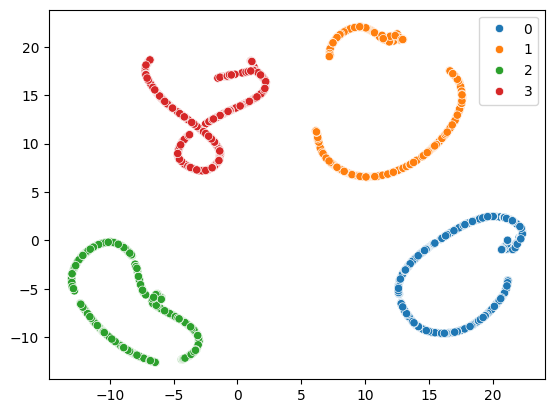

In [ ]:
# Visualizing clustering
ax = sns.scatterplot(x=X_umap[:,0],y=X_umap[:,1],hue=dbscan.labels_,palette=sns.color_palette())

In [339]:
# Writing submission
with open('submission_8.csv','w') as f:
    f.write('ID,cluster\n')
    for i in range(len(dbscan.labels_)):
        f.write(f'{i},{dbscan.labels_[i]}\n')

#### Identifying server locations

In [10]:
# Reading csv to get the column names
data_ = pd.read_csv('unsupervised_data.csv')

In [11]:
# Sorting rows (numerically not lexicographically)
cols_sorted = sorted(data_.columns, key=lambda x: int(x.split('_')[1]))

In [12]:
# Rearranging dataframe
data_ = data_.reindex((cols_sorted),axis=1)
data_.head()

,col_0,col_1,col_2,col_3,col_4,col_5,col_6,col_7,col_8,col_9,...,col_16374,col_16375,col_16376,col_16377,col_16378,col_16379,col_16380,col_16381,col_16382,col_16383
0,0.646305,0.646305,0.646305,0.646305,0.646305,0.646305,0.646305,0.646305,0.646305,0.646305,...,0.475593,0.532497,0.589401,0.627337,0.655790,0.665273,0.674758,0.665273,0.655790,0.646305
1,-0.144320,0.383794,0.633953,0.578363,0.587628,0.587628,0.587628,0.587628,0.587628,0.587628,...,0.587628,0.587628,0.587628,0.587628,0.578363,0.457915,0.068779,0.087309,0.494976,0.457915
2,0.590203,0.590203,0.590203,0.590203,0.590203,0.367673,0.345897,0.367673,0.367673,0.367673,...,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203
3,0.551415,0.551415,0.551415,0.551415,0.551415,0.551415,0.551415,0.551415,0.551415,0.551415,...,0.589296,0.589296,0.589296,0.589296,0.589296,0.589296,0.589296,0.589296,0.589296,0.589296
4,0.672652,0.672655,0.672929,0.677057,0.688611,0.646499,0.409348,0.064447,-0.087393,-0.085845,...,0.672652,0.672652,0.672652,0.672652,0.672652,0.672652,0.672652,0.672652,0.672652,0.672652


In [13]:
# ID 0 was assigned cluster 0. let's examine
data_.iloc[0,:].describe()

count    16384.000000
mean         0.500023
std          0.200042
min         -1.013399
25%          0.247976
50%          0.627337
75%          0.646305
max          1.000000
Name: 0, dtype: float64

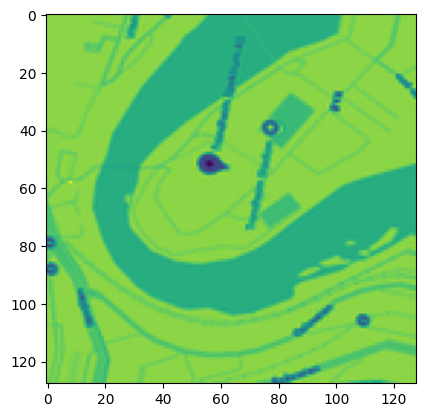

In [ ]:
# Plotting as heatmap
plt.imshow(data_.iloc[0,:].to_numpy().reshape(128,128))
plt.show() # wow, unexpected

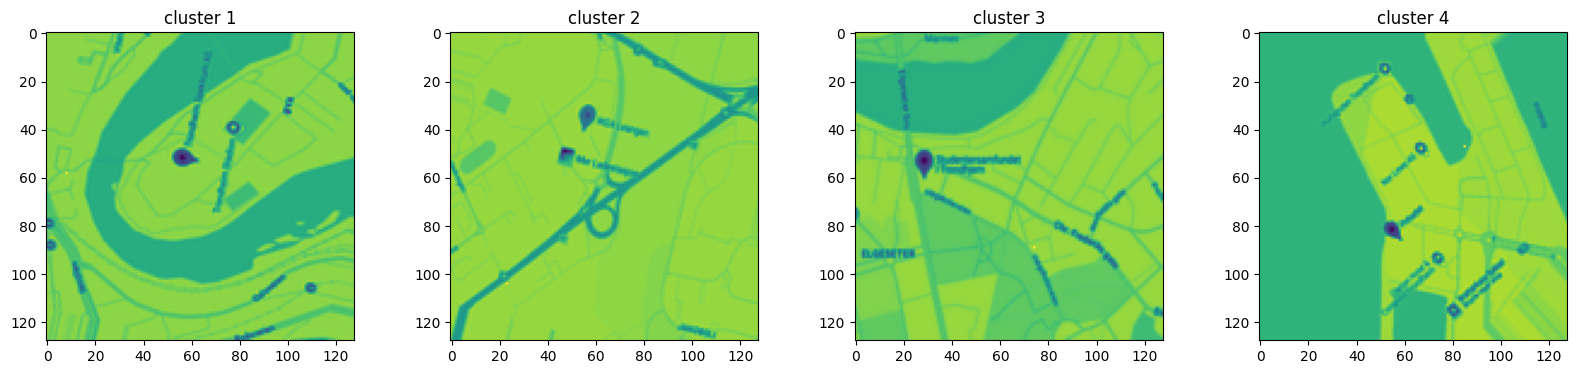

In [15]:
# Trying the same with a sample from each cluster (choosing ones that give nice images)
fig, axes = plt.subplots(1,4,figsize=(20,4))
axes[0].imshow(data_.iloc[0,:].to_numpy().reshape(128,128))
axes[1].imshow(data_.iloc[11,:].to_numpy().reshape(128,128))
axes[2].imshow(data_.iloc[24,:].to_numpy().reshape(128,128))
axes[3].imshow(data_.iloc[13,:].to_numpy().reshape(128,128))
axes[0].set_title('cluster 1')
axes[1].set_title('cluster 2')
axes[2].set_title('cluster 3')
axes[3].set_title('cluster 4')
plt.show()

In [ ]:
# Locations are Spektrum, IKEA Leangen, Samf, Pirbadet


---

## 🎯 Note: Clustering Accuracy Evaluation

The clustering accuracy metric evaluates how well the predicted clusters match the true clusters, irrespective of the specific labels or names assigned to the clusters.

This means that the evaluation is solely based on the correct grouping of data points rather than the numerical labels of the clusters themselves.

## Key Characteristics

- **Name-Independent**: The metric cares only about how well the data points are grouped together, not the specific numerical or categorical labels used for the clusters.
- **Focus on Grouping**: The evaluation rewards cluster assignments that correctly group the same data points together, regardless of the specific labels assigned.

### Example

If the true cluster assignments are:

```
[0, 0, 0, 1, 1, 1]
```

and your predicted cluster assignments are:

```
[1, 1, 1, 0, 0, 0]
```

the accuracy will still be **1.0** because the grouping of points is identical, even though the numerical labels are swapped.

## How the Metric is Computed

1. **Contingency Matrix**: 
   - Construct a contingency matrix that represents the overlap between the true clusters and the predicted clusters.

2. **Optimal Correspondence**: 
   - Use an optimization algorithm, such as the Hungarian method (linear sum assignment), to find the best possible correspondence between true and predicted labels, maximizing the number of correctly assigned data points.

3. **Accuracy Calculation**: 
   - Calculate the accuracy as the ratio of correctly matched data points to the total number of data points.

> This approach ensures that the evaluation is based on **cluster completeness** and **homogeneity**, rewarding cluster assignments that correctly group the same data points together, regardless of the specific labels used.

---

In [ ]:
import numpy as np
import scipy.optimize
import sklearn.metrics

def calculate_clustering_accuracy(true_labels: np.ndarray, cluster_labels: np.ndarray) -> float:
    """
    Calculate the clustering accuracy between true labels and cluster labels.

    The function constructs a contingency matrix between the true labels and cluster labels.
    It then uses the Hungarian algorithm (also known as linear sum assignment) to find the
    best matching between the cluster labels and true labels. The clustering accuracy is 
    calculated as the number of correctly matched labels divided by the total number of labels.

    Args:
        true_labels (np.ndarray): An array of true labels for each data point.
        cluster_labels (np.ndarray): An array of cluster labels predicted by a clustering algorithm.

    Returns:
        float: The clustering accuracy, a value between 0 and 1 representing the proportion of  
               correctly matched labels.
    
    Example:
        >>> true_labels = np.array([0, 1, 2, 0, 1, 2])
        >>> cluster_labels = np.array([1, 2, 0, 1, 2, 0])
        >>> calculate_clustering_accuracy(true_labels, cluster_labels)
        1.0

    Raises:
        ValueError: If true_labels and cluster_labels are not of the same length.
    """
    # Check if the input labels are of the same length
    if true_labels.size != cluster_labels.size:
        raise ValueError("true_labels and cluster_labels must have the same length.")

    # Construct a contingency matrix where each cell [i, j] indicates the number of points with 
    # true label i and cluster label j.
    contingency_matrix = sklearn.metrics.cluster.contingency_matrix(true_labels, cluster_labels)
    
    # Find the best matching between true labels and cluster labels using the Hungarian algorithm.
    # We negate the contingency matrix because linear_sum_assignment finds the minimum cost assignment.
    row_ind, col_ind = scipy.optimize.linear_sum_assignment(-contingency_matrix)
    
    # Calculate the number of correctly assigned labels according to the optimal matching.
    correct_pairs = contingency_matrix[row_ind, col_ind].sum()
    
    # Compute the clustering accuracy as the ratio of correctly matched labels to total labels.
    accuracy = correct_pairs / true_labels.size

    return accuracy

In [9]:
true_labels = np.array([0, 1, 2, 0, 1, 2])
cluster_labels = np.array([1, 2, 0, 1, 2, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(1.0)

In [10]:
true_labels = np.array([0, 0, 0, 0, 0, 0])
cluster_labels = np.array([1, 2, 0, 1, 2, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(0.3333333333333333)

In [11]:
true_labels = np.array([1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 0, 0, 0, 0, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(0.5)